# PCS26/84 — DEEP LEARNING-BASED FAKE NEWS DETECTION

## Notebook 05 — Final Evaluation, Error Analysis, Explainability and Shortcut Analysis

| | |
|---|---|
| **Project code** | PCS26/84 |
| **Project title** | DEEP LEARNING-BASED FAKE NEWS DETECTION |
| **Position** | Notebook 5 of 5 (01 audit → 02 ML → 03 LSTM/BiLSTM → 04 transformer → **05 evaluation & explainability**) |
| **Labels** | **Fake = 0, Real = 1** |



### 5.1 Introduction and research questions
High accuracy on a benchmark is a weak argument for a fake-news detector: if the classes differ in publisher, format or topic, a model can succeed without understanding veracity ("shortcut learning", Geirhos et al., 2020). A final evaluation therefore needs three things beyond a leaderboard: **uncertainty-aware comparison**, **error analysis**, and **evidence about what the models actually use**.

* **RQ1** How do the classical models and the LSTM/BiLSTM (and the transformer, if executed) compare on identical validation examples, and are the differences meaningful?
* **RQ2** Where do the models fail, and do they fail on the same articles?
* **RQ3** Which words/n-grams drive the linear models, and which spans drive the neural models?
* **RQ4** Is there direct evidence that a model relies on publisher markers or headline style?
* **RQ5** Are the saved artefacts reloadable and reproducible, and can a new article be scored safely?

### Evaluation protocol and honest test-set history
* All model comparison and selection used the **validation** set (Notebooks 02–04).
* **A Linear SVM trained on raw title + body (V0) was evaluated once on the test set in the original project, before Phase 1.** The test set is therefore **not untouched**, and no claim in this project says otherwise. That result was not used for any selection.
* Phase 1 test evaluations (Notebooks 02, 03, 04) are single-use, off-by-default cells. This notebook only *reads* their stored results if they exist.
* Explainability and shortcut experiments here use **validation data only**.

### Methods used (with limits)
* **Paired exact McNemar test** (Dietterich, 1998) for two models on the same examples; with near-ceiling models the number of discordant pairs is tiny, so most differences are *not* significant.
* **Coefficient analysis** of linear models: weight × TF-IDF value decomposes a prediction into additive n-gram contributions. These are *associations in the training data*, not causal effects.
* **Occlusion** (Zeiler & Fergus, 2014): mask a window of tokens and measure the change in P(Real). It is model-agnostic but depends on window size and on what "masking" means; interactions between spans are ignored. **Attention weights are not used** as explanations (Jain & Wallace, 2019).
* **Counterfactual perturbations** (inject/remove a marker) to test reliance directly.

### Structure
5.2 dataset & protocol · 5.3 consolidated comparison · 5.4 classification metrics · 5.5 confusion matrices & curves · 5.6 error analysis · 5.7 explainability (linear) · 5.8 explainability (neural) · 5.9 shortcut & leakage analysis · 5.10 prediction demo · 5.11 artefact verification · 5.12 results & discussion · 5.13 conclusion & future scope · 5.14 final checklist.

### How to run
Run Notebooks 01–03 (and 04 if possible) first, then **Restart & Run All** (≈ 10–15 min on a laptop CPU). Requires `src/`, `torch scikit-learn pandas numpy matplotlib seaborn joblib scipy`.

In [1]:
from pathlib import Path
import hashlib
import json
import os
import sys
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_recall_fscore_support, roc_curve)
from sklearn.svm import LinearSVC

warnings.filterwarnings("default")


def find_project_root(marker="dataset"):
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / marker).is_dir():
            return candidate
    raise FileNotFoundError(f"No '{marker}/' folder found above {here}.")


PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "dataset" / "combined_fake_news_clean.csv"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
MODELS_DIR = PROJECT_ROOT / "models"
PH1_DIR = MODELS_DIR / "phase1"
NOTEBOOKS_DIR = PROJECT_ROOT / "notebooks"
SRC_DIR = PROJECT_ROOT / "src"
for d in (TABLES_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(SRC_DIR))
import fakenews_utils as fu
import fakenews_dl as dl

SEED = 42
RUN_COUNTERFACTUAL = True          # refits ONE V0 Linear SVM (~2-4 min) for the injection experiment
N_OCCLUSION_PER_CLASS = 60
OCCLUSION_WINDOW = 5
np.random.seed(SEED); torch.manual_seed(SEED)
print("Project root:", PROJECT_ROOT)

required = [TABLES_DIR / "p1_val_predictions_all_variants.csv", TABLES_DIR / "p1_eligible_rows.csv",
            PH1_DIR / "ml_selected_config.json", PH1_DIR / "ml_selected_pipeline.joblib"]
missing = [str(p.relative_to(PROJECT_ROOT)) for p in required if not p.exists()]
if missing:
    raise FileNotFoundError("Run Notebook 02 first. Missing: " + ", ".join(missing))

Project root: C:\Users\mi\Desktop\Fake-news detection


## 5.2 Dataset and evaluation protocol
**What:** summarise the data actually used (sizes, classes, label mapping, eligible rows) and re-verify integrity. **Why:** every later number depends on these being right. **Output:** split table, integrity checks, hash status. **Interpretation:** all checks must pass; "eligible rows" are those with usable text under every input variant, so the same examples are scored for every model.

In [2]:
df = pd.read_csv(DATA_PATH)
manifest = pd.read_csv(TABLES_DIR / "data_split_manifest.csv")
part_idx = {p: manifest.loc[manifest.partition == p, "row_index"].astype(int).to_numpy() for p in ("train", "validation", "test")}
train_df, val_df, test_df = (df.iloc[part_idx[p]].copy() for p in ("train", "validation", "test"))

rows = []
for name, frame in (("train", train_df), ("validation", val_df), ("test", test_df)):
    rows.append({"partition": name, "records": len(frame), "Fake (0)": int((frame.label == 0).sum()),
                 "Real (1)": int((frame.label == 1).sum()), "Fake share %": round(100 * (frame.label == 0).mean(), 1)})
split_table = pd.DataFrame(rows)
display(split_table)
print("Total cleaned records:", len(df), "| label mapping:", fu.LABEL_MAP)

keys = fu.article_key(df["title"], df["text"])
gs = {p: set(keys.iloc[i]) for p, i in part_idx.items()}
integrity = pd.DataFrame([
    ("Each row in exactly one partition", set(manifest.row_index) == set(range(len(df))) and manifest.row_index.is_unique),
    ("No identical title+body group across partitions", gs["train"].isdisjoint(gs["validation"]) and gs["train"].isdisjoint(gs["test"]) and gs["validation"].isdisjoint(gs["test"])),
    ("Labels are {0,1}; Fake=0, Real=1", set(df.label.unique()) == {0, 1} and fu.LABEL_MAP == {"Fake": 0, "Real": 1}),
    ("subject / date are not model inputs (ArticleTextBuilder reads only title and text)",
     "subject" not in __import__("inspect").getsource(fu.ArticleTextBuilder._fields) and "date" not in __import__("inspect").getsource(fu.ArticleTextBuilder._fields)),
], columns=["Check", "Passed"])
display(integrity)
assert integrity["Passed"].all()

registry = fu.HashRegistry(TABLES_DIR / "phase1_hash_registry.json", PROJECT_ROOT)
print("manifest:", registry.check(TABLES_DIR / "data_split_manifest.csv"), "| clean CSV:", registry.check(DATA_PATH))

el = pd.read_csv(TABLES_DIR / "p1_eligible_rows.csv")
display(el.groupby("partition")["eligible"].agg(rows="size", eligible="sum").assign(dropped=lambda d: d.rows - d.eligible))
ml_cfg = json.loads((PH1_DIR / "ml_selected_config.json").read_text())
VARIANT, RULES = ml_cfg["signature"]["variant"], ml_cfg["signature"]["active_rules"]
print(f"Frozen input variant {VARIANT}: {ml_cfg['input_description']} | {len(RULES)} marker rules")

,partition,records,Fake (0),Real (1),Fake share %
0,train,30796,15906,14890,51.6
1,validation,6652,3523,3129,53.0
2,test,6610,3419,3191,51.7


Total cleaned records: 44058 | label mapping: {'Fake': 0, 'Real': 1}


,Check,Passed
0,Each row in exactly one partition,True
1,No identical title+body group across partitions,True
2,"Labels are {0,1}; Fake=0, Real=1",True
3,subject / date are not model inputs (ArticleTe...,True


manifest: verified | clean CSV: verified


,rows,eligible,dropped
partition,,,
train,30796,30735,61
validation,6652,6643,9


Frozen input variant V3: Title + body, publisher markers removed | 12 marker rules


## 5.3 Consolidated model comparison (validation set)
**What:** one table of every successfully evaluated model on the **same eligible validation rows and the same marker-stripped input** (variant V3 in the verification run). Rows come from the stored artefacts of Notebooks 02–04; a model appears only if its result file exists. **Why:** comparisons are only meaningful when inputs, rows and metrics are identical. **Interpretation:** compare macro-F1 and ROC-AUC, but translate differences into *numbers of examples*: a 0.001 difference in accuracy on ~6 600 rows is about 7 articles.

,model,n,accuracy,precision_fake,recall_fake,precision_real,recall_real,macro_f1,roc_auc,errors
0,Linear SVM,6643,0.9929,0.9951,0.9915,0.9905,0.9946,0.9929,0.9997,47
1,Logistic Regression,6643,0.9892,0.9917,0.9878,0.9863,0.9907,0.9891,0.9994,72
2,BiLSTM,6643,0.9892,0.9940,0.9855,0.9839,0.9933,0.9891,0.9993,72
3,"ML (info-matched, first 200 tokens)",6643,0.9871,0.9925,0.9829,0.9810,0.9917,0.9870,0.9992,86
4,LSTM,6643,0.9842,0.9874,0.9826,0.9806,0.9859,0.9841,0.9965,105
5,Multinomial Naive Bayes,6643,0.9556,0.9605,0.9553,0.9501,0.9559,0.9555,0.9895,295


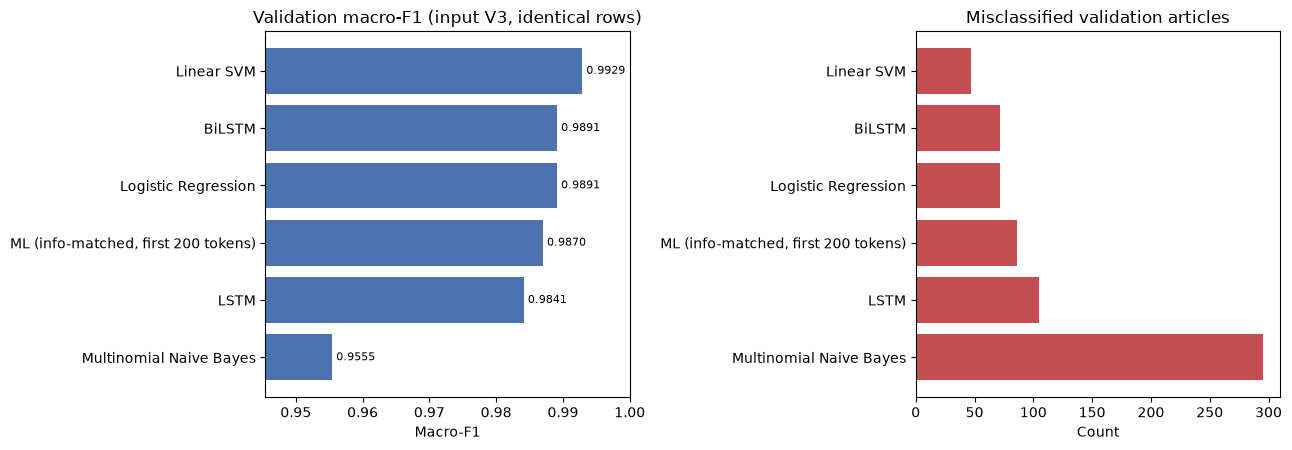


Full ablation (macro-F1 by input variant and model) from Notebook 02:


model,Linear SVM,Logistic Regression,Multinomial NB
variant,,,
V0,0.9970,0.9943,0.9610
V1,0.9953,0.9928,0.9589
V2,0.9584,0.9590,0.9470
V3,0.9929,0.9891,0.9555
V4,0.9893,0.9848,0.9529



Paired exact McNemar tests on validation (Notebook 03):


,model_A,model_B,a_right_b_wrong,a_wrong_b_right,p_value
0,BiLSTM,LSTM,92,59,0.0090
1,BiLSTM,"ML (frozen, full text)",39,64,0.0176
2,LSTM,"ML (frozen, full text)",36,94,0.0000
3,BiLSTM,"ML (info-matched, first 200 tokens)",70,56,0.2467


In [3]:
abl = pd.read_csv(TABLES_DIR / "p1_ablation_validation_metrics.csv")
sel = abl[abl.variant == VARIANT].copy()
sel["model"] = sel["model"].map({"Logistic Regression": "Logistic Regression", "Multinomial NB": "Multinomial Naive Bayes", "Linear SVM": "Linear SVM"})
cols = ["model", "n", "accuracy", "precision_fake", "recall_fake", "precision_real", "recall_real", "macro_f1", "roc_auc"]
comp = sel[cols].copy()

dlp = TABLES_DIR / "p1_dl_validation_comparison.csv"
if dlp.exists():
    d = pd.read_csv(dlp)
    d = d[d.model.isin(["LSTM", "BiLSTM"]) | d.model.str.startswith("ML (info-matched")][cols]
    comp = pd.concat([comp, d], ignore_index=True)
else:
    print("LSTM/BiLSTM validation results not found (run Notebook 03) - they are absent from the table.")
trp = TABLES_DIR / "p1_transformer_validation_metrics.csv"
if trp.exists():
    t = pd.read_csv(trp)
    if int(t["rows"].iloc[0]) == int(comp["n"].iloc[0]) and "SMOKE" not in str(t["model"].iloc[0]):
        t = t.assign(model="DistilBERT (fine-tuned)", n=t["rows"])[cols]; comp = pd.concat([comp, t], ignore_index=True)
else:
    print("Transformer validation results not found: the transformer experiment (Notebook 04) was not executed or not comparable.")

comp["errors"] = (comp["n"] * (1 - comp["accuracy"])).round().astype(int)
display(comp.round(4).sort_values("macro_f1", ascending=False).reset_index(drop=True))
comp.to_csv(TABLES_DIR / "p1_consolidated_validation_comparison.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
order = comp.sort_values("macro_f1")
ax[0].barh(order["model"], order["macro_f1"], color="#4C72B0"); ax[0].set_xlim(max(0.9, order["macro_f1"].min() - 0.01), 1.0)
ax[0].set_title(f"Validation macro-F1 (input {VARIANT}, identical rows)"); ax[0].set_xlabel("Macro-F1")
for i, v in enumerate(order["macro_f1"]): ax[0].text(v, i, f" {v:.4f}", va="center", fontsize=8)
ax[1].barh(order["model"], order["errors"], color="#C44E52"); ax[1].set_title("Misclassified validation articles"); ax[1].set_xlabel("Count")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "24_consolidated_validation_comparison.png", dpi=300, bbox_inches="tight"); plt.show()

print("\nFull ablation (macro-F1 by input variant and model) from Notebook 02:")
display(abl.pivot(index="variant", columns="model", values="macro_f1").round(4))

mc = TABLES_DIR / "p1_dl_validation_mcnemar.csv"
if mc.exists():
    print("\nPaired exact McNemar tests on validation (Notebook 03):")
    display(pd.read_csv(mc).round(4))

**Test-set results (only if the single-use cells were run).** The cell below *reads* stored final-test results; it never evaluates the test set itself.

In [4]:
shown = False
for name, path in (("ML + DL final test comparison (Notebook 03)", TABLES_DIR / "p1_final_test_comparison.csv"),):
    if path.exists():
        print(name); display(pd.read_csv(path).round(4)); shown = True
for name, path in (("Frozen ML model final test (Notebook 02)", TABLES_DIR / "p1_ml_final_test_results.json"),
                   ("Transformer final test (Notebook 04)", TABLES_DIR / "p1_transformer_final_test_results.json")):
    if path.exists():
        print(name); print(json.dumps(json.loads(path.read_text()), indent=2)[:1200]); shown = True
if not shown:
    print("No Phase 1 final-test results are stored: the single-use final-test cells have not been run.")
legacy = TABLES_DIR / "svm_test_results.csv"
print("\nLegacy (pre-Phase-1) V0 Linear SVM test result - observed earlier, NOT used for selection:",
      "file present" if legacy.exists() else "file not in this project folder")
if legacy.exists():
    display(pd.read_csv(legacy))

ML + DL final test comparison (Notebook 03)


,model,n,accuracy,precision_fake,recall_fake,precision_real,recall_real,macro_f1,roc_auc,accuracy_ci_lo,accuracy_ci_hi,macro_f1_ci_lo,macro_f1_ci_hi
0,BiLSTM (frozen),6609,0.9894,0.9938,0.9857,0.9848,0.9934,0.9894,0.9995,0.9862,0.9925,0.9862,0.9924
1,"ML (frozen, full text)",6609,0.9920,0.9965,0.9880,0.9873,0.9962,0.9920,0.9996,0.9890,0.9947,0.9889,0.9947
2,"ML (info-matched, first 200 tokens)",6609,0.9871,0.9900,0.9851,0.9841,0.9893,0.9871,0.9989,0.9837,0.9904,0.9837,0.9904



Legacy (pre-Phase-1) V0 Linear SVM test result - observed earlier, NOT used for selection: file present


,Model,Accuracy,Precision,Recall,F1-Score
0,Linear SVM,0.995915,0.99345,0.99812,0.995779


## 5.4 Classification metrics
**What:** per-class precision, recall, F1 and support, plus macro and weighted averages, for each model on the identical validation rows. Predictions of the classical models are read from Notebook 02's saved table; the LSTM/BiLSTM predictions are recomputed from their saved checkpoints with the frozen preprocessing (this also tests reload compatibility). **Metric definitions:** with Real as the positive class, precision(Real)=TP/(TP+FP) is the share of articles flagged Real that are Real; recall(Real) is the share of Real articles found; the Fake-class values are defined symmetrically. *Macro* averages the two classes equally; *weighted* averages by support. **Interpretation:** inspect the asymmetry (a model can be better at one class), not only the average.

In [5]:
P = pd.read_csv(TABLES_DIR / "p1_val_predictions_all_variants.csv")
rows_idx = P["row_index"].to_numpy()
y = P["label"].to_numpy(int)
val_el = df.loc[rows_idx]
print("Eligible validation rows:", len(val_el))

PRED = {}   # model name -> (hard prediction, continuous score for P/R and ROC)
for model_name, label in (("Logistic Regression", "Logistic Regression"), ("Multinomial NB", "Multinomial Naive Bayes"), ("Linear SVM", "Linear SVM")):
    PRED[label] = (P[f"{VARIANT}|{model_name}|pred"].to_numpy(int), P[f"{VARIANT}|{model_name}|score"].to_numpy(float))

# ---- frozen text builder -> neural inputs
ml_bundle = fu.load_bundle(PH1_DIR / "ml_selected_pipeline.joblib")
assert fu.sha256_file(PH1_DIR / "ml_selected_pipeline.joblib") == ml_cfg["bundle_sha256"]
ml_builder = ml_bundle["pipeline"].named_steps["text"]
t0 = time.time()
val_texts = ml_builder.transform(val_el)
print(f"Frozen preprocessing applied to validation ({time.time() - t0:.0f}s)")

DL = {}
for arch in ("LSTM", "BiLSTM"):
    ck_path = PH1_DIR / f"{arch.lower()}_phase1_best.pt"
    if not ck_path.exists():
        print(f"{arch}: checkpoint not found (run Notebook 03) - skipped"); continue
    model, vocab, cfg, ck = dl.load_checkpoint(ck_path, "cpu")
    ds = dl.EncodedDataset(val_texts, y, vocab, cfg["max_len"])
    prob, lab = dl.predict_proba(model, dl.make_loader(ds, 128, shuffle=False), "cpu")
    assert (lab == y).all()
    PRED[arch] = ((prob >= 0.5).astype(int), prob)
    DL[arch] = (model, vocab, cfg)
    print(f"{arch}: reloaded checkpoint (best epoch {ck['best_epoch']}) and scored {len(y)} rows")

tp = TABLES_DIR / "p1_transformer_val_predictions.csv"
if tp.exists():
    T = pd.read_csv(tp)
    if len(T) == len(y) and (T["row_index"].to_numpy() == rows_idx).all():
        PRED["DistilBERT (fine-tuned)"] = ((T["prob_real"] >= 0.5).astype(int).to_numpy(), T["prob_real"].to_numpy())

rows = []
for name, (pred, score) in PRED.items():
    p, r, f, s = precision_recall_fscore_support(y, pred, labels=[0, 1], zero_division=0)
    pm, rm, fm, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(y, pred, average="weighted", zero_division=0)
    rows.append({"model": name, "P_Fake": p[0], "R_Fake": r[0], "F1_Fake": f[0], "support_Fake": int(s[0]),
                 "P_Real": p[1], "R_Real": r[1], "F1_Real": f[1], "support_Real": int(s[1]),
                 "macro_P": pm, "macro_R": rm, "macro_F1": fm, "weighted_F1": fw})
class_metrics = pd.DataFrame(rows)
display(class_metrics.round(4))
class_metrics.to_csv(TABLES_DIR / "p1_class_metrics_validation.csv", index=False)

Eligible validation rows: 6643
Frozen preprocessing applied to validation (6s)
LSTM: reloaded checkpoint (best epoch 5) and scored 6643 rows
BiLSTM: reloaded checkpoint (best epoch 4) and scored 6643 rows


,model,P_Fake,R_Fake,F1_Fake,support_Fake,P_Real,R_Real,F1_Real,support_Real,macro_P,macro_R,macro_F1,weighted_F1
0,Logistic Regression,0.9917,0.9878,0.9897,3514,0.9863,0.9907,0.9885,3129,0.9890,0.9892,0.9891,0.9892
1,Multinomial Naive Bayes,0.9605,0.9553,0.9579,3514,0.9501,0.9559,0.9530,3129,0.9553,0.9556,0.9555,0.9556
2,Linear SVM,0.9951,0.9915,0.9933,3514,0.9905,0.9946,0.9925,3129,0.9928,0.9930,0.9929,0.9929
3,LSTM,0.9874,0.9826,0.9850,3514,0.9806,0.9859,0.9833,3129,0.9840,0.9843,0.9841,0.9842
4,BiLSTM,0.9940,0.9855,0.9897,3514,0.9839,0.9933,0.9885,3129,0.9889,0.9894,0.9891,0.9892


## 5.5 Confusion matrices and performance curves
**What:** a confusion matrix per model (rows = actual class, columns = predicted) and ROC / precision–recall curves drawn from each model's **continuous score** (SVM margin, LR log-odds, NB/DL probability). **Why:** matrices show *which kind* of error occurs; curves show ranking quality independent of the 0.5/0 threshold. **Interpretation:** curves hugging the top-left (ROC) or top-right (PR) mean near-perfect ranking; at this level they overlap, so zoom on the high-recall end and compare AUC values only to the precision the data allow.

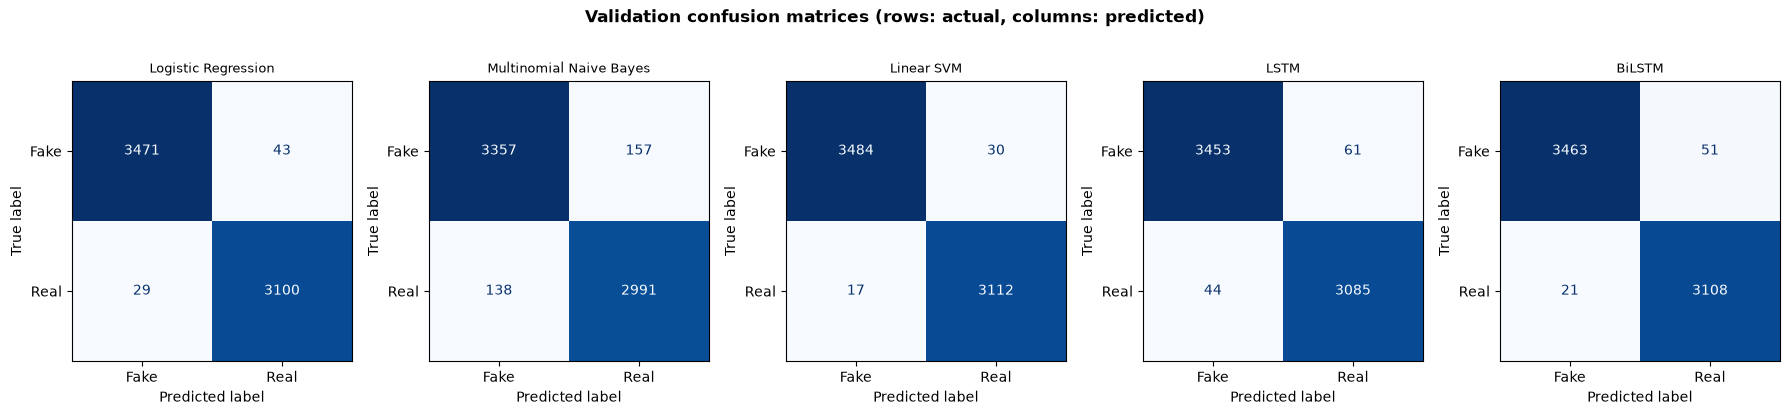

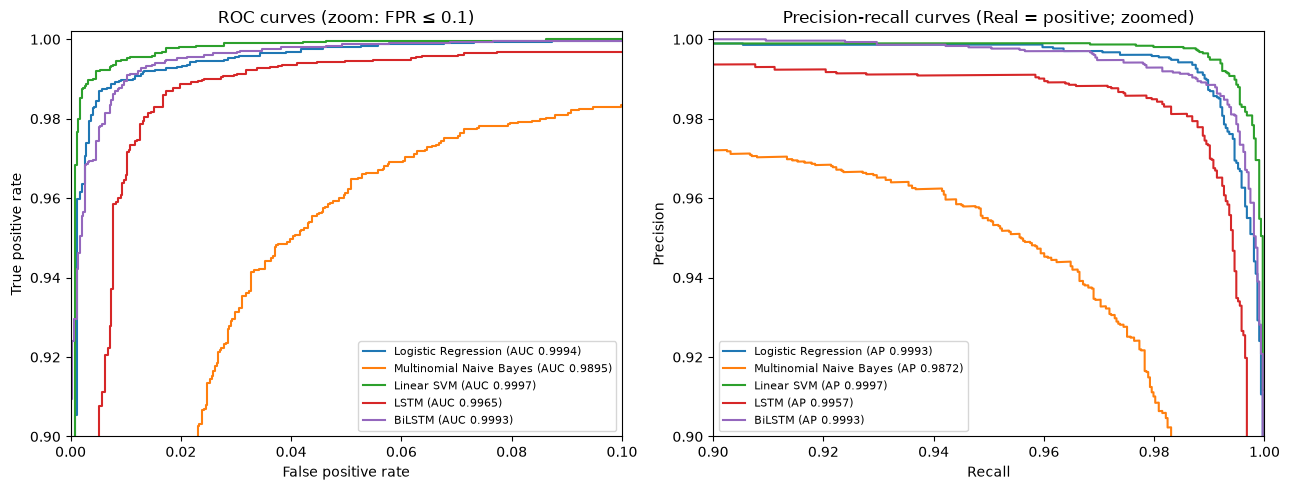

,model,roc_auc,average_precision
0,Logistic Regression,0.99938,0.99931
1,Multinomial Naive Bayes,0.98952,0.98723
2,Linear SVM,0.99973,0.99970
3,LSTM,0.99648,0.99573
4,BiLSTM,0.99933,0.99935


In [6]:
names = list(PRED)
fig, axes = plt.subplots(1, len(names), figsize=(3.6 * len(names), 3.9))
for ax, name in zip(np.atleast_1d(axes), names):
    cm = confusion_matrix(y, PRED[name][0], labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["Fake", "Real"]).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(name, fontsize=9)
plt.suptitle("Validation confusion matrices (rows: actual, columns: predicted)", y=1.02, fontweight="bold")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "25_validation_confusion_matrices.png", dpi=300, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
auc_rows = []
for name, (pred, score) in PRED.items():
    fpr, tpr, _ = roc_curve(y, score); pr, rc, _ = precision_recall_curve(y, score)
    from sklearn.metrics import roc_auc_score
    auc = roc_auc_score(y, score); ap = average_precision_score(y, score)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {auc:.4f})"); ax[1].plot(rc, pr, label=f"{name} (AP {ap:.4f})")
    auc_rows.append({"model": name, "roc_auc": auc, "average_precision": ap})
ax[0].plot([0, 1], [0, 1], "k--", lw=.7); ax[0].set_xlim(0, 0.1); ax[0].set_ylim(0.9, 1.002)
ax[0].set_title("ROC curves (zoom: FPR ≤ 0.1)"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].legend(fontsize=8, loc="lower right")
ax[1].set_xlim(0.9, 1.0); ax[1].set_ylim(0.9, 1.002)
ax[1].set_title("Precision-recall curves (Real = positive; zoomed)"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "26_validation_roc_pr_curves.png", dpi=300, bbox_inches="tight"); plt.show()
display(pd.DataFrame(auc_rows).round(5))

## 5.6 Error analysis
**What:** which articles are misclassified, by how many models, and what they have in common. **Why:** models that make *different* errors suggest independent evidence; articles *every* model gets wrong are either genuinely ambiguous, mislabelled, or atypical of their class. **Method:** error counts per model, an overlap table, breakdowns by subject, body length, truncation and duplicate-group membership (for *description only* — `subject` is never a model input), and the hardest examples. **Caution:** only patterns visible in these tables are claimed; with a few dozen errors per model, breakdowns are suggestive, not conclusive.

In [7]:
wrong = pd.DataFrame({n: (PRED[n][0] != y) for n in PRED}, index=rows_idx)
wrong["n_models_wrong"] = wrong.sum(axis=1)
overlap = pd.DataFrame({"errors": wrong[list(PRED)].sum(),
                        "errors shared with ALL other models": [int((wrong[n] & (wrong["n_models_wrong"] == len(PRED))).sum()) for n in PRED]})
display(overlap)
print(f"Articles misclassified by at least one model: {int((wrong.n_models_wrong > 0).sum())} | by ALL {len(PRED)} models: {int((wrong.n_models_wrong == len(PRED)).sum())}")

info = val_el[["title", "text", "subject", "label"]].copy()
info["body_words"] = info["text"].astype(str).str.split().str.len().to_numpy()
info["dup_group_size"] = keys.loc[rows_idx].map(keys.value_counts()).to_numpy()
info["n_models_wrong"] = wrong["n_models_wrong"].to_numpy()
info["any_wrong"] = info["n_models_wrong"] > 0
lens = np.array([len(dl.tokenize(t)) for t in val_texts])
info["truncated_at_200"] = lens > 200
info["length_bucket"] = pd.cut(info["body_words"], [0, 50, 150, 400, 1000, 10**6], labels=["<=50", "51-150", "151-400", "401-1000", ">1000"])

def rate_table(col):
    g = info.groupby(col, observed=True).agg(rows=("any_wrong", "size"), articles_with_an_error=("any_wrong", "sum"), mean_models_wrong=("n_models_wrong", "mean"))
    g["error_rate_%"] = (100 * g["articles_with_an_error"] / g["rows"]).round(2)
    return g.round(3)

for col in ("label", "subject", "length_bucket", "truncated_at_200"):
    print(f"\nBy {col} (description only):"); display(rate_table(col))
dup = info.assign(in_repeated_group=info["dup_group_size"] > 1)
print("\nBy membership of a repeated title+body group:"); display(rate_table("dup_group_size").head(0)); display(
    dup.groupby("in_repeated_group").agg(rows=("any_wrong", "size"), articles_with_an_error=("any_wrong", "sum")).assign(rate_pct=lambda d: (100 * d.articles_with_an_error / d.rows).round(2)))

hard = info[info.n_models_wrong > 0].sort_values("n_models_wrong", ascending=False).head(12)
print("\nHardest articles (most models wrong):")
display(hard.assign(text_start=hard["text"].astype(str).str.slice(0, 180))[["title", "text_start", "subject", "label", "n_models_wrong", "body_words"]])
info.drop(columns=["text"]).assign(**{n: wrong[n].to_numpy() for n in PRED}).to_csv(TABLES_DIR / "p1_error_analysis_validation.csv")

,errors,errors shared with ALL other models
Logistic Regression,72,3
Multinomial Naive Bayes,295,3
Linear SVM,47,3
LSTM,105,3
BiLSTM,72,3


Articles misclassified by at least one model: 426 | by ALL 5 models: 3

By label (description only):


,rows,articles_with_an_error,mean_models_wrong,error_rate_%
label,,,,
0,3514,236,0.097,6.72
1,3129,190,0.080,6.07



By subject (description only):


,rows,articles_with_an_error,mean_models_wrong,error_rate_%
subject,,,,
Government News,243,41,0.255,16.87
Middle-east,112,8,0.107,7.14
News,1360,57,0.055,4.19
US_News,112,8,0.107,7.14
left-news,672,41,0.082,6.10
politics,1015,81,0.124,7.98
politicsNews,1626,137,0.105,8.43
worldnews,1503,53,0.052,3.53



By length_bucket (description only):


... (4 outputs left out)

,rows,articles_with_an_error,mean_models_wrong,error_rate_%
dup_group_size,,,,


,rows,articles_with_an_error,rate_pct
in_repeated_group,,,
False,5007,306,6.11
True,1636,120,7.33



Hardest articles (most models wrong):


,title,text_start,subject,label,n_models_wrong,body_words
26402,FEDERAL PROSECUTOR Working On Plea Deal For IS...,A plea deal for this punk will really make ano...,politics,0,5,500
18610,JUST IN: Helicopter Crashes In Saudi Arabia KI...,"Zero Hedge In a shocking development, late o...",politics,0,5,578
16774,INTERNET: Living with the Great Firewall of China,(Reuters) - The Great Firewall of China th...,worldnews,1,5,399
37118,Special Report: Why an emblematic American cit...,"MUNCIE, Indiana (Reuters) - One night a month...",politicsNews,1,4,2428
43660,"UNITED AIRLINES GROUNDED, WALL STREET JOURNAL ...","So the NYSE, Wall Street Journal and United Ai...",Government News,0,4,684
22970,OBAMA UNLEASHES HUNDREDS Of Intelligence Agent...,We all know by now that the biggest threat to ...,left-news,0,4,320
22832,Mother's fight to discover fate of dead baby's...,EDINBURGH (Reuters) - A mother who has been fi...,worldnews,1,4,425
16006,BREAKING: NORTH KOREA Detains American Student...,Apparently it takes just one American student ...,Government News,0,4,219
15870,BREAKING: NORTH KOREA Detains American Student...,Apparently it takes just one American student ...,politics,0,4,219
10674,SENATE PASSES USA FREEDOM ACT,McConnell was shut down completely in this deb...,Government News,0,4,441


In [8]:
# Auto-generated reading of the tables above (computed, not typed).
worst = info[info.n_models_wrong == len(PRED)]
by_label = info.groupby("label")["any_wrong"].mean() * 100
msg = [f"* {int((info.any_wrong).sum())} of {len(info)} validation articles ({100 * info.any_wrong.mean():.2f} %) are misclassified by at least one model; "
       f"{len(worst)} are misclassified by all {len(PRED)}.",
       f"* Share of articles with at least one error: Fake {by_label.get(0, float('nan')):.2f} %, Real {by_label.get(1, float('nan')):.2f} %.",
       f"* Median body length of articles with an error: {info.loc[info.any_wrong, 'body_words'].median():.0f} words vs {info.loc[~info.any_wrong, 'body_words'].median():.0f} for correctly classified ones.",
       f"* Truncated (>200 token) articles: error rate {100 * info.loc[info.truncated_at_200, 'any_wrong'].mean():.2f} % vs {100 * info.loc[~info.truncated_at_200, 'any_wrong'].mean():.2f} % for shorter ones."]
display(Markdown("\n".join(msg)))

* 426 of 6643 validation articles (6.41 %) are misclassified by at least one model; 3 are misclassified by all 5.
* Share of articles with at least one error: Fake 6.72 %, Real 6.07 %.
* Median body length of articles with an error: 422 words vs 357 for correctly classified ones.
* Truncated (>200 token) articles: error rate 7.07 % vs 3.75 % for shorter ones.

**Reading the error analysis.** Look for (i) whether a class dominates the errors, (ii) whether errors concentrate in short or in truncated inputs, (iii) whether repeated groups are over-represented (the same article listed twice counts twice), and (iv) whether the hardest articles look *atypical of their class* — for example an interview or special report on the Real side, or sensational wire-style text on the Fake side. Such cases support the view that the models learn **style regularities of each source** more than veracity. Any such statement must be backed by the tables printed in your run.

## 5.7 Explainability for traditional models
**What:** (a) *global* weights of the frozen Linear SVM (TF-IDF n-grams → signed weights); (b) *local* explanations of single articles: the decision margin is `Σ wⱼ·xⱼ + b`, so each n-gram's contribution `wⱼ·xⱼ` shows how much it pushed that article toward Real (+) or Fake (−). **Why:** linear models are transparent, so this is a faithful description of *what the model computes*. **Limits:** weights describe correlations in the training data; they do not show that a word *causes* an article to be fake, correlated n-grams share credit arbitrarily, and the model has no notion of truth.

In [9]:
pipe = ml_bundle["pipeline"]
tfidf, clf = pipe.named_steps["tfidf"], pipe.named_steps["clf"]
glob_tbl = fu.top_linear_features(tfidf, clf, n=25)
print(f"Frozen model: {ml_cfg['signature']['model']} on variant {VARIANT} - strongest n-grams (positive -> Real, negative -> Fake)")
display(glob_tbl.round(3))
glob_tbl.to_csv(TABLES_DIR / "p1_frozen_model_top_features.csv", index=False)


def explain_linear(title, body, k=8):
    frame = pd.DataFrame({"title": [title], "text": [body]})
    x = tfidf.transform(pipe.named_steps["text"].transform(frame))
    coef = np.asarray(clf.coef_).ravel()
    nz = x.nonzero()[1]
    contrib = pd.DataFrame({"ngram": np.asarray(tfidf.get_feature_names_out())[nz], "contribution": coef[nz] * np.asarray(x[0, nz].todense()).ravel()})
    margin = float(contrib.contribution.sum() + clf.intercept_[0])
    return margin, contrib.sort_values("contribution")

pick = {}
svm_pred = PRED["Linear SVM"][0]
for key, cond in (("correct Fake", (y == 0) & (svm_pred == 0)), ("correct Real", (y == 1) & (svm_pred == 1)),
                  ("error: Fake predicted Real", (y == 0) & (svm_pred == 1)), ("error: Real predicted Fake", (y == 1) & (svm_pred == 0))):
    if cond.any():
        pick[key] = int(np.flatnonzero(cond)[0])
for key, i in pick.items():
    row = val_el.iloc[i]
    margin, ctb = explain_linear(row["title"], row["text"])
    print(f"\n=== {key} | true {fu.ID_TO_LABEL[int(row['label'])]} | margin {margin:+.3f} | {str(row['title'])[:90]}")
    print("  most Fake-ward:", ", ".join(f"{a} ({b:+.2f})" for a, b in ctb.head(6).itertuples(index=False)))
    print("  most Real-ward:", ", ".join(f"{a} ({b:+.2f})" for a, b in ctb.tail(6).iloc[::-1].itertuples(index=False)))

Frozen model: Linear SVM on variant V3 - strongest n-grams (positive -> Real, negative -> Fake)


,rank,toward_Fake,weight_Fake,toward_Real,weight_Real
0,1,via,-5.350,said,5.622
1,2,video,-4.799,said on,3.734
2,3,read more,-3.644,president donald,3.299
3,4,president trump,-2.776,on tuesday,2.948
4,5,gop,-2.734,on wednesday,2.920
5,6,the us,-2.619,on,2.746
6,7,read,-2.605,on thursday,2.708
7,8,this,-2.493,on friday,2.451
8,9,just,-2.492,said in,2.318
9,10,us,-2.373,on monday,2.186



=== correct Fake | true Fake | margin -0.922 |  OOPS: Trump Just Accidentally Confirmed He Leaked Israeli Intelligence To Russia (VIDEO)
  most Fake-ward: video (-0.14), president trump (-0.12), just (-0.10), watch (-0.08), us (-0.07), you (-0.06)
  most Real-ward: said (+0.20), on monday (+0.08), trump said (+0.06), on (+0.06), minister (+0.05), israel (+0.04)

=== correct Real | true Real | margin +1.082 | U.S. House panel offers alternative to retirement adviser rule
  most Fake-ward: rep (-0.07), obama (-0.05), just (-0.04), that the (-0.03), this (-0.03), that (-0.03)
  most Real-ward: said (+0.14), on wednesday (+0.07), president barack (+0.05), on (+0.05), version (+0.05), lawmakers (+0.05)

=== error: Fake predicted Real | true Fake | margin +0.068 | SWEDISH CITIZENS Get DISTURBING News About Likely Punishment For ASYLUM SEEKERS Who Live-S
  most Fake-ward: video (-0.09), mr (-0.07), breitbart (-0.05), is (-0.04), this (-0.03), facebook (-0.03)
  most Real-ward: said (+0.14), 

## 5.8 Explainability for the neural models (token-window occlusion)
**Method.** For an article, the first 200 tokens (what the network sees) are divided into windows of 5 tokens. Each window is replaced in turn by the unknown-token id and the change `Δ = P(Real | original) − P(Real | occluded)` is recorded: **Δ > 0** means the window supported *Real*, **Δ < 0** supported *Fake*. Per-token scores are the window score divided by the window length. **Why:** it needs no access to model internals and works for LSTM, BiLSTM or a transformer. **Limits:** results depend on window size and on the masking choice; replacing text with an unknown token creates unnatural inputs; effects of *combinations* of spans can be missed; and a saturated model (P ≈ 1) shows tiny Δ even for important spans. Attention weights are deliberately **not** shown as explanations. Section result = *what changes this model's output*, not *what makes the news false*.

Occlusion model: BiLSTM (the architecture selected on validation in Notebook 03)

Mean token attribution over 120 random validation articles (tokens with >=8 occurrences):


,Real-ward token,Real-ward mean_delta,Real-ward occurrences,Fake-ward token,Fake-ward mean_delta,Fake-ward occurrences
0,presidential,0.0035,26,korea,-0.0116,14
1,me,0.0013,11,north,-0.0095,17
2,talk,0.0012,8,why,-0.0094,19
3,u,0.0012,79,nuclear,-0.0044,12
4,campaign,0.0009,32,act,-0.0025,8
5,city,0.0009,9,this,-0.0024,71
6,raqqa,0.0008,14,video,-0.0023,33
7,islamic,0.0008,15,american,-0.0022,18
8,ahead,0.0007,9,during,-0.0021,20
9,many,0.0005,17,two,-0.0013,22


Unigram overlap between the SVM's top-25 n-grams per direction and the neural model's top-40 tokens per direction: ['gop', 'is', 'republican', 'said', 'this', 'tuesday', 'us', 'video', 'why']

--- val row 34026 | true Fake | P(Real)=0.000 | THE VIEW’S LOUDMOUTH LIBERAL Joy Behar Calls Bill Clinton’s Rape Victims “TRAMPS
  Real-ward windows: 'rape .' (+0.000) | 'the view ' s joy' (+0.000) | 'can certainly connect with a' (+0.000)
  Fake-ward windows: 'the view ’ s loudmouth' (-0.004) | 'liberal joy behar calls bill' (-0.002) | 'clinton ’ s rape victims' (-0.000)

--- val row 2800 | true Fake | P(Real)=0.000 | MEDIA IGNORES! Huge List of Attacks on Conservatives is Shocking
  Real-ward windows: 'assisting his agenda . if' (+0.000) | 'narrative anytime something happens between' (+0.000) | '. just as destructive as' (-0.000)
  Fake-ward windows: 'media ignores ! huge list' (-0.001) | 'you ve noticed a hijacking' (-0.000) | 'of attacks on conservatives is' (-0.000)

--- val row 14355 | tru

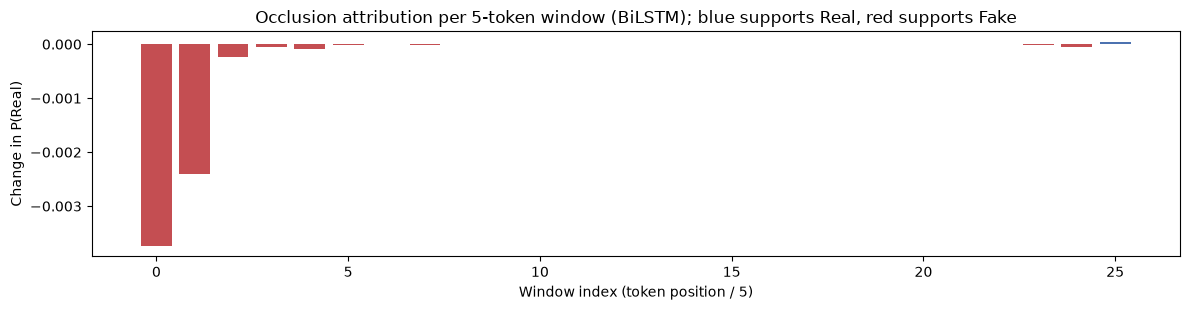

In [10]:
@torch.no_grad()
def occlusion(model, vocab, cfg, model_input, window=OCCLUSION_WINDOW):
    toks = dl.tokenize(model_input)[:cfg["max_len"]]
    if not toks:
        return toks, float("nan"), [], np.array([])
    ids = [vocab.get(t, dl.UNK_ID) for t in toks]
    L = len(ids)
    batch, spans = [ids], []
    for s in range(0, L, window):
        v = list(ids)
        for j in range(s, min(L, s + window)):
            v[j] = dl.UNK_ID
        batch.append(v); spans.append((s, min(L, s + window)))
    x = torch.tensor(batch)
    p = torch.softmax(model(x, torch.full((len(batch),), L)), dim=1)[:, 1].numpy()
    return toks, float(p[0]), spans, p[0] - p[1:]


OCC_ARCH = None
if DL:
    sel_cfg_path = PH1_DIR / "dl_selected_config.json"
    OCC_ARCH = json.loads(sel_cfg_path.read_text())["signature"]["selected"] if sel_cfg_path.exists() else list(DL)[0]
    model, vocab, cfg = DL[OCC_ARCH]
    print(f"Occlusion model: {OCC_ARCH} (the architecture selected on validation in Notebook 03)")
    rng = np.random.default_rng(SEED)
    pos_by_class = {c: rng.choice(np.flatnonzero(y == c), N_OCCLUSION_PER_CLASS, replace=False) for c in (0, 1)}

    tok_scores, example_rows = {}, []
    for c, idxs in pos_by_class.items():
        for i in idxs:
            toks, base, spans, delta = occlusion(model, vocab, cfg, val_texts[i])
            for (s, e), dlt in zip(spans, delta):
                for t in toks[s:e]:
                    tok_scores.setdefault(t, []).append(dlt / (e - s))
            if len(example_rows) < 4 and ((c == 0 and len(example_rows) < 2) or (c == 1 and len(example_rows) >= 2)):
                example_rows.append((i, toks, base, spans, delta))

    agg = pd.DataFrame([(t, np.mean(v), len(v)) for t, v in tok_scores.items() if len(v) >= 8], columns=["token", "mean_delta", "occurrences"])
    agg = agg[agg.token.str.match(r"^[a-z0-9]+$")]
    print(f"\nMean token attribution over {2 * N_OCCLUSION_PER_CLASS} random validation articles (tokens with >=8 occurrences):")
    display(pd.concat([agg.sort_values("mean_delta", ascending=False).head(15).reset_index(drop=True).add_prefix("Real-ward "),
                       agg.sort_values("mean_delta").head(15).reset_index(drop=True).add_prefix("Fake-ward ")], axis=1).round(4))
    agg.to_csv(TABLES_DIR / "p1_occlusion_token_attribution.csv", index=False)

    svm_top = set(glob_tbl.toward_Real) | set(glob_tbl.toward_Fake)
    dl_top = set(agg.sort_values("mean_delta", ascending=False).head(40).token) | set(agg.sort_values("mean_delta").head(40).token)
    print("Unigram overlap between the SVM's top-25 n-grams per direction and the neural model's top-40 tokens per direction:", sorted(svm_top & dl_top))

    for i, toks, base, spans, delta in example_rows:
        order = np.argsort(delta)
        print(f"\n--- val row {rows_idx[i]} | true {fu.ID_TO_LABEL[int(y[i])]} | P(Real)={base:.3f} | {str(val_el.iloc[i]['title'])[:80]}")
        for tag, sel_ in (("Real-ward", order[::-1][:3]), ("Fake-ward", order[:3])):
            print(f"  {tag} windows:", " | ".join(f"'{' '.join(toks[spans[k][0]:spans[k][1]])}' ({delta[k]:+.3f})" for k in sel_))

    # figure: one example as a bar of per-window attributions
    i, toks, base, spans, delta = example_rows[0]
    fig, ax = plt.subplots(figsize=(12, 3.2))
    ax.bar(range(len(delta)), delta, color=np.where(delta >= 0, "#4C72B0", "#C44E52"))
    ax.set_title(f"Occlusion attribution per {OCCLUSION_WINDOW}-token window ({OCC_ARCH}); blue supports Real, red supports Fake")
    ax.set_xlabel(f"Window index (token position / {OCCLUSION_WINDOW})"); ax.set_ylabel("Change in P(Real)")
    plt.tight_layout(); plt.savefig(FIGURES_DIR / "27_occlusion_example.png", dpi=300, bbox_inches="tight"); plt.show()
else:
    print("No neural checkpoint available (run Notebook 03): occlusion analysis skipped.")

**Reading the occlusion results.** Compare the Real-ward and Fake-ward token lists with the Linear SVM's top n-grams: *agreement* between two very different model families on the same stylistic or format tokens (rather than topical words) is evidence that both learned the same dataset regularities; *disagreement* shows model-specific behaviour. Remember that occlusion Δ is small when the network is already very confident, and that these are model-behaviour explanations, not fact checks.

## 5.9 Shortcut and leakage analysis
**What:** consolidate the evidence from Notebooks 01–02 and add *direct tests of reliance* on shortcuts, using validation data only. **Why:** a high score is only informative if it is not explained by publisher markers, headline style or duplicates. **Evidence types:** (a) stored dataset/ablation/duplicate evidence; (b) accuracy on subsets with and without a marker; (c) **counterfactual perturbation** — inject the Reuters dateline into Fake articles and remove it from Real ones using a V0 Linear SVM refitted on training rows (same hyper-parameters as Notebook 02), and swap headlines between classes for the frozen model; (d) evaluation on de-duplicated and near-duplicate-free views for every model. `subject` and `date` remain excluded.

In [11]:
print("(a) Evidence stored by Notebooks 01-02")
for title, f in (("Marker prevalence in the training partition", "marker_rule_prevalence_train.csv"),
                 ("Univariate formatting AUC (training)", "univariate_formatting_auc_train.csv"),
                 ("Near-duplicates of training articles", "near_duplicate_summary.csv"),
                 ("Identical bodies/titles across partitions", "partial_overlap_cross_partition.csv")):
    p_ = TABLES_DIR / f
    if p_.exists():
        print(f"\n{title}:"); display(pd.read_csv(p_).round(4))
print("\nAblation (validation macro-F1, Linear SVM) - what happens when headline/markers are removed:")
display(abl[abl.model == "Linear SVM"][["variant", "input", "accuracy", "macro_f1", "roc_auc"]].round(4).reset_index(drop=True))

(a) Evidence stored by Notebooks 01-02

Marker prevalence in the training partition:


,rule,description,prevalence_fake,prevalence_real,skew_ratio,selected
0,dateline_reuters,Leading '[CITY] (Reuters) -' dateline (seen in...,0.0001,0.9842,875.1146,True
1,reuters_token,Any remaining 'Reuters' token,0.0133,0.9984,69.7492,True
2,reporting_by_credit,Wire-style '(Reporting by ...; Editing by ...)...,0.0000,0.0155,16.5138,True
3,century_wire,'21st Century Wire (says)' (seen in a Fake sam...,0.0541,0.0000,55.0676,True
4,featured_image,'Featured image (via ...)' caption phrase,0.3392,0.0000,340.1802,True
5,image_credit,'Photo/Image via|credit' caption phrase,0.2852,0.0000,286.2383,True
6,getty_images,'Getty Images' credit,0.1705,0.0000,171.5017,True
7,pic_twitter,Embedded tweet picture link,0.1503,0.0000,151.3206,True
8,url,URLs,0.1453,0.0020,48.5247,True
9,twitter_handle,@handles,0.2669,0.0123,20.1563,True



Univariate formatting AUC (training):


,feature,roc_auc_for_Real,separation_|2*AUC-1|
0,title_words,0.1258,0.7485
1,title_chars,0.1151,0.7698
2,body_words,0.4673,0.0654
3,body_chars,0.4813,0.0374



Near-duplicates of training articles:


,partition,class,articles,sim>=0.99,sim>=0.95,sim>=0.90,sim>=0.80,median_max_sim
0,validation,Fake,3523,19,40,57,92,0.231
1,validation,Real,3129,69,80,89,101,0.389
2,test,Fake,3419,27,40,68,98,0.235
3,test,Real,3191,64,71,80,107,0.387



Identical bodies/titles across partitions:


,check,groups_crossing_partitions
0,Identical bodies that appear in more than one ...,10
1,Identical titles that appear in more than one ...,176



Ablation (validation macro-F1, Linear SVM) - what happens when headline/markers are removed:


,variant,input,accuracy,macro_f1,roc_auc
0,V0,Raw title + body,0.9970,0.9970,0.9999
1,V1,Body only (raw),0.9953,0.9953,0.9999
2,V2,Title only (raw),0.9585,0.9584,0.9922
3,V3,"Title + body, publisher markers removed",0.9929,0.9929,0.9997
4,V4,"Body only, publisher markers removed",0.9893,0.9893,0.9995


In [12]:
# (b) Subset analysis: V0 vs frozen model on articles WITH vs WITHOUT a Reuters dateline (validation).
raw_text = val_el["text"].astype(str)
has_dateline = raw_text.map(lambda s: bool(fu.RULES_BY_NAME["dateline_reuters"]["regex"].search(s) and fu.RULES_BY_NAME["dateline_reuters"]["regex"].search(s).end() > 0)).to_numpy()
has_furniture = raw_text.map(lambda s: any(fu.RULES_BY_NAME[r]["regex"].search(s) for r in ("featured_image", "image_credit", "getty_images", "pic_twitter", "url", "watch_label"))).to_numpy()
v0_pred = P["V0|Linear SVM|pred"].to_numpy(int)
fz_pred = PRED["Linear SVM"][0]
rows = []
for grp, mask in (("Real WITH Reuters dateline", (y == 1) & has_dateline), ("Real WITHOUT dateline", (y == 1) & ~has_dateline),
                  ("Fake WITH page furniture", (y == 0) & has_furniture), ("Fake WITHOUT page furniture", (y == 0) & ~has_furniture)):
    n = int(mask.sum())
    rows.append({"group": grp, "n": n,
                 "V0 SVM accuracy": float((v0_pred[mask] == y[mask]).mean()) if n else np.nan,
                 "frozen model accuracy": float((fz_pred[mask] == y[mask]).mean()) if n else np.nan})
display(pd.DataFrame(rows).round(4))
print("Small groups (n < ~50) give very noisy accuracies; read them as hints only.")

,group,n,V0 SVM accuracy,frozen model accuracy
0,Real WITH Reuters dateline,3094,0.9984,0.9948
1,Real WITHOUT dateline,35,0.9714,0.9714
2,Fake WITH page furniture,1854,0.9989,0.9973
3,Fake WITHOUT page furniture,1660,0.9928,0.9849


Small groups (n < ~50) give very noisy accuracies; read them as hints only.


In [13]:
# (c) Counterfactual perturbations
rule_dateline = fu.RULES_BY_NAME["dateline_reuters"]["regex"]
cf_rows = []
if RUN_COUNTERFACTUAL:
    el_tr = el[(el.partition == "train") & el.eligible].row_index
    tr_el = df.loc[el_tr]
    t0 = time.time()
    b0 = fu.make_builder("V0").fit(tr_el)
    tf0 = fu.make_tfidf(); X0 = tf0.fit_transform(b0.transform(tr_el))
    svm0 = LinearSVC(C=1.0, max_iter=3000, random_state=SEED).fit(X0, tr_el["label"].to_numpy(int))
    pipe0 = fu.assemble_pipeline(b0, tf0, svm0)
    print(f"V0 Linear SVM refitted on {len(tr_el):,} eligible training rows ({time.time() - t0:.0f}s)")
    if "v0_pred" in globals():
       assert (pipe0.predict(val_el[["title", "text"]]) == v0_pred).mean() > 0.995, \
        "refit disagrees with Notebook 02's V0 predictions"
    else:
       print("WARNING: Notebook 02 V0 predictions unavailable; consistency check skipped.")

    fake_val = val_el[val_el.label == 0][["title", "text"]]
    real_val = val_el[val_el.label == 1][["title", "text"]]
    inj = fake_val.assign(text=lambda d: "WASHINGTON (Reuters) - " + d.text.astype(str))
    stripped = real_val.assign(text=lambda d: d.text.astype(str).map(lambda s: rule_dateline.sub("", s, count=1)))
    for name, p_ in (("V0 Linear SVM (raw input)", pipe0), ("Frozen model (marker-stripped input)", pipe)):
        cf_rows.append({"model": name, "perturbation": "inject 'WASHINGTON (Reuters) -' into FAKE articles",
                        "baseline % predicted Real": 100 * float((p_.predict(fake_val) == 1).mean()),
                        "after % predicted Real": 100 * float((p_.predict(inj) == 1).mean())})
        cf_rows.append({"model": name, "perturbation": "remove leading dateline from REAL articles",
                        "baseline % predicted Fake": 100 * float((p_.predict(real_val) == 0).mean()),
                        "after % predicted Fake": 100 * float((p_.predict(stripped) == 0).mean())})
else:
    print("RUN_COUNTERFACTUAL is False - skipped.")

# headline swap for the frozen model: replace each title with a random title of the OPPOSITE class
rng = np.random.default_rng(SEED)
titles_fake = val_el.loc[val_el.label == 0, "title"].to_numpy(); titles_real = val_el.loc[val_el.label == 1, "title"].to_numpy()
swapped = val_el[["title", "text"]].copy()
swapped["title"] = [rng.choice(titles_real) if lab == 0 else rng.choice(titles_fake) for lab in y]
for name, p_ in ((f"Frozen model ({VARIANT}, uses title)", pipe),):
    base_acc = float((p_.predict(val_el[["title", "text"]]) == y).mean()); sw_acc = float((p_.predict(swapped) == y).mean())
    cf_rows.append({"model": name, "perturbation": "swap each headline with a random headline of the OTHER class",
                    "baseline accuracy %": 100 * base_acc, "after accuracy %": 100 * sw_acc})
cf = pd.DataFrame(cf_rows)
display(cf.round(2))
cf.to_csv(TABLES_DIR / "p1_counterfactual_tests_validation.csv", index=False)

V0 Linear SVM refitted on 30,735 eligible training rows (37s)


,model,perturbation,baseline % predicted Real,after % predicted Real,baseline % predicted Fake,after % predicted Fake,baseline accuracy %,after accuracy %
0,V0 Linear SVM (raw input),inject 'WASHINGTON (Reuters) -' into FAKE arti...,0.40,4.95,NaN,NaN,NaN,NaN
1,V0 Linear SVM (raw input),remove leading dateline from REAL articles,NaN,NaN,0.19,0.99,NaN,NaN
2,Frozen model (marker-stripped input),inject 'WASHINGTON (Reuters) -' into FAKE arti...,0.85,0.85,NaN,NaN,NaN,NaN
3,Frozen model (marker-stripped input),remove leading dateline from REAL articles,NaN,NaN,0.54,0.54,NaN,NaN
4,"Frozen model (V3, uses title)",swap each headline with a random headline of t...,NaN,NaN,NaN,NaN,99.29,97.97


In [14]:
# (d) Robustness of every model to duplicates: macro-F1 on full / de-duplicated / near-duplicate-free views.
gi = pd.read_csv(TABLES_DIR / "split_group_info.csv").set_index("row_index") if (TABLES_DIR / "split_group_info.csv").exists() else None
views = {"all eligible": np.ones(len(y), bool), "de-duplicated": ~keys.loc[rows_idx].duplicated().to_numpy()}
if gi is not None:
    views["near-duplicate-free (<0.90)"] = gi.loc[rows_idx, "near_dup_max_sim"].to_numpy() < 0.90
rows = []
for name, (pred, score) in PRED.items():
    r = {"model": name}
    for vn, m in views.items():
        r[vn] = f1_score(y[m], pred[m], average="macro")
    rows.append(r)
display(pd.DataFrame(rows).round(4)); print("Rows per view:", {k: int(m.sum()) for k, m in views.items()})

,model,all eligible,de-duplicated,near-duplicate-free (<0.90)
0,Logistic Regression,0.9891,0.9891,0.9889
1,Multinomial Naive Bayes,0.9555,0.9563,0.9548
2,Linear SVM,0.9929,0.9931,0.9927
3,LSTM,0.9841,0.9849,0.9846
4,BiLSTM,0.9891,0.9889,0.9889


Rows per view: {'all eligible': 6643, 'de-duplicated': 5792, 'near-duplicate-free (<0.90)': 6505}


In [15]:
# Auto-generated reading of section 5.9 (computed values)
lines = []
for _, r in cf.iterrows():
    if "inject" in r["perturbation"]:
        lines.append(f"* {r['model']}: injecting a Reuters dateline moves {r['baseline % predicted Real']:.1f} % -> {r['after % predicted Real']:.1f} % of FAKE validation articles to 'Real'.")
    elif "remove" in r["perturbation"]:
        lines.append(f"* {r['model']}: removing the dateline moves {r['baseline % predicted Fake']:.1f} % -> {r['after % predicted Fake']:.1f} % of REAL validation articles to 'Fake'.")
    else:
        lines.append(f"* {r['model']}: swapping headlines across classes changes accuracy from {r['baseline accuracy %']:.2f} % to {r['after accuracy %']:.2f} %.")
display(Markdown("**Counterfactual results (validation):**\n\n" + "\n".join(lines)))

**Counterfactual results (validation):**

* V0 Linear SVM (raw input): injecting a Reuters dateline moves 0.4 % -> 5.0 % of FAKE validation articles to 'Real'.
* V0 Linear SVM (raw input): removing the dateline moves 0.2 % -> 1.0 % of REAL validation articles to 'Fake'.
* Frozen model (marker-stripped input): injecting a Reuters dateline moves 0.9 % -> 0.9 % of FAKE validation articles to 'Real'.
* Frozen model (marker-stripped input): removing the dateline moves 0.5 % -> 0.5 % of REAL validation articles to 'Fake'.
* Frozen model (V3, uses title): swapping headlines across classes changes accuracy from 99.29 % to 97.97 %.

**Reading section 5.9.** A large jump after *injecting* a marker is direct evidence that the raw-input model uses that marker; the marker-stripped frozen model is protected against these particular markers *by construction*, so the useful comparison is the raw-input model against the stripped one. The headline-swap test measures how much the frozen model (which includes the title) depends on the headline; a large accuracy drop means headline style matters. Marker removal cannot guarantee the absence of other shortcuts (Notebook 02 shows format tokens remaining), so the honest conclusion is: **performance reflects dataset regularities, partly publisher and style related, and must not be presented as truth detection.**

## 5.10 Prediction demonstration
**What:** one function takes a headline and body and returns, for each available model, the predicted **dataset label** and a **score**. **Why:** it shows that reloaded artefacts apply the *same preprocessing* as training. **Important:** a score is a measure of similarity to the training classes — **not** a probability that the claims are true. Inputs with fewer than ~20 words are flagged as unreliable, empty input is rejected, and the model does not know about events after its training data.

In [16]:
DISCLAIMER = fu.DISCLAIMER
_dl_cache = {}


def predict_news(title, body):
    """Returns a dict of per-model predictions. Predicts the dataset label (Fake=0/Real=1); does NOT verify facts."""
    out = {"disclaimer": DISCLAIMER}
    base = fu.predict_article(title, body, ml_bundle)
    out["ML (frozen " + ml_cfg["signature"]["model"] + ")"] = base
    if base.get("label") is None:
        return out
    text = ml_builder.transform(pd.DataFrame({"title": [title or ""], "text": [body or ""]}))[0]
    for arch in ("LSTM", "BiLSTM"):
        ck = PH1_DIR / f"{arch.lower()}_phase1_best.pt"
        if not ck.exists():
            continue
        if arch not in _dl_cache:
            _dl_cache[arch] = dl.load_checkpoint(ck, "cpu")
        m, v, c, _ = _dl_cache[arch]
        p = dl.predict_text(m, v, c, text, "cpu")
        out[arch] = {"label": fu.ID_TO_LABEL[int(p >= 0.5)], "probability_real": p}
    return out


for k in (0, 1):
    i = int(np.flatnonzero(y == k)[3])
    row = val_el.iloc[i]
    print(f"\nValidation article (true label {fu.ID_TO_LABEL[int(row['label'])]}): {str(row['title'])[:90]}")
    for name, res in predict_news(row["title"], row["text"]).items():
        if name != "disclaimer":
            print(f"   {name:28s} ->", {kk: (round(vv, 4) if isinstance(vv, float) else vv) for kk, vv in res.items() if kk in ("label", "probability_real", "decision_margin", "warning")})
print("\nVery short input:", predict_news("Short test", "Prices rose today.")["ML (frozen " + ml_cfg["signature"]["model"] + ")"])
print("Empty input:", predict_news("", "")["ML (frozen " + ml_cfg["signature"]["model"] + ")"])
print("\n" + DISCLAIMER)


Validation article (true label Fake):  Republicans Dine With Trump, Then Try To Railroad Comey Into Clearing Him (VIDEO)
   ML (frozen Linear SVM)       -> {'label': 'Fake', 'decision_margin': -1.587}
   LSTM                         -> {'label': 'Fake', 'probability_real': 0.0022}
   BiLSTM                       -> {'label': 'Fake', 'probability_real': 0.0}

Validation article (true label Real): Trump says only role for U.S. in Libya is defeating Islamic State
   ML (frozen Linear SVM)       -> {'label': 'Real', 'decision_margin': 1.1348}
   LSTM                         -> {'label': 'Real', 'probability_real': 0.9998}
   BiLSTM                       -> {'label': 'Real', 'probability_real': 1.0}

Very short input: {'label': 'Fake', 'label_id': 0, 'n_words_used': 5, 'disclaimer': "This model predicts whether an article resembles the 'Fake' or 'Real' class of its training dataset. It does not verify factual claims.", 'decision_margin': -0.1500656660249557, 'margin_note': 'Signed margin (

## 5.11 Model reloading and artefact verification
**What:** verify that saved files are the ones that were frozen (SHA-256 against the stored configuration / registry), that reloading reproduces the stored predictions, and list the **legacy** checkpoints without touching them. **Why:** reproducibility and protection of existing work. **Interpretation:** every row should read OK; a mismatch means a file changed after freezing.

In [17]:
checks = []
def add_check(name, ok, detail=""):
    checks.append({"check": name, "result": "OK" if ok else "FAIL", "detail": detail})

add_check("Frozen ML bundle hash equals stored configuration", fu.sha256_file(PH1_DIR / "ml_selected_pipeline.joblib") == ml_cfg["bundle_sha256"])
n = 200
re_pred = ml_bundle["pipeline"].predict(val_el.iloc[:n][["title", "text"]])
add_check("Reloaded ML pipeline reproduces stored validation predictions (first 200 rows)", (re_pred == PRED["Linear SVM"][0][:n]).all())
dlc = PH1_DIR / "dl_selected_config.json"
if dlc.exists():
    dcfg = json.loads(dlc.read_text())
    add_check("Selected DL checkpoint hash equals stored configuration", fu.sha256_file(PH1_DIR / dcfg["checkpoint"]) == dcfg["checkpoint_sha256"], dcfg["checkpoint"])
    imp = PH1_DIR / dcfg["info_matched_svm"]
    add_check("Information-matched SVM hash equals stored configuration", fu.sha256_file(imp) == dcfg["info_matched_sha256"])
for arch, (model, vocab, cfg) in DL.items():
    ds = dl.EncodedDataset(val_texts[:100], y[:100], vocab, cfg["max_len"])
    prob2, _ = dl.predict_proba(model, dl.make_loader(ds, 50, shuffle=False), "cpu")
    add_check(f"Reloaded {arch} reproduces its scores (first 100 rows)", np.abs(prob2 - PRED[arch][1][:100]).max() < 1e-5)
    add_check(f"{arch} checkpoint stores vocabulary, architecture and label mapping", {"vocab_size", "label_mapping", "max_len"} <= set(cfg))
add_check("Label mapping stored with models equals project mapping", ml_bundle["label_map"] == fu.LABEL_MAP)
add_check("Hash registry: manifest unchanged", registry.check(TABLES_DIR / "data_split_manifest.csv", strict=False) in ("verified", "recorded"))
vf = tfidf.idf_
n_est = 3 * np.exp(vf.max() - 1) - 1          # a term with df=2 has idf = ln((1+n)/3)+1  ->  n
n_train_el = int(((el.partition == "train") & el.eligible).sum())
add_check("TF-IDF was fitted on training rows only (implied document count equals eligible TRAIN rows)", abs(n_est - n_train_el) < 2,
          f"implied {n_est:.0f} vs {n_train_el}")
display(pd.DataFrame(checks))
pd.DataFrame(checks).to_csv(TABLES_DIR / "p1_artifact_verification.csv", index=False)

print("\nLegacy artefacts present in models/ (read-only; never modified here):")
leg = []
for p_ in sorted(MODELS_DIR.glob("*.pt")):
    entry = {"file": p_.name, "MB": round(p_.stat().st_size / 1e6, 2), "sha256[:12]": fu.sha256_file(p_)[:12]}
    try:
        obj = torch.load(p_, map_location="cpu", weights_only=True)
        sd = obj.get("model_state_dict", obj) if isinstance(obj, dict) else {}
        entry["top-level keys"] = ",".join(list(obj.keys())[:5]) if isinstance(obj, dict) else type(obj).__name__
        entry["tensors"] = len(sd)
    except Exception as exc:
        entry["note"] = f"not loadable with weights_only=True ({type(exc).__name__})"
    leg.append(entry)
display(pd.DataFrame(leg)) if leg else print("none found")
print("Compatibility of legacy checkpoints with the Phase 1 architecture is NOT assumed: they used raw input and unpacked padding.")

,check,result,detail
0,Frozen ML bundle hash equals stored configuration,OK,
1,Reloaded ML pipeline reproduces stored validat...,OK,
2,Selected DL checkpoint hash equals stored conf...,OK,bilstm_phase1_best.pt
3,Information-matched SVM hash equals stored con...,OK,
4,Reloaded LSTM reproduces its scores (first 100...,OK,
5,"LSTM checkpoint stores vocabulary, architectur...",OK,
6,Reloaded BiLSTM reproduces its scores (first 1...,OK,
7,"BiLSTM checkpoint stores vocabulary, architect...",OK,
8,Label mapping stored with models equals projec...,OK,
9,Hash registry: manifest unchanged,OK,



Legacy artefacts present in models/ (read-only; never modified here):


,file,MB,sha256[:12],top-level keys,tensors
0,bilstm_best.pt,5.79,0a48daef9b6e,"model_state_dict,vocab,config,best_epoch,best_...",11
1,bilstm_best_corrected.pt,5.79,d1abfa368200,"model_state_dict,vocab,config,best_epoch,best_...",11
2,bilstm_best_epoch2_backup.pt,5.79,0a48daef9b6e,"model_state_dict,vocab,config,best_epoch,best_...",11
3,lstm_best.pt,5.66,739da65c8163,"model_state_dict,vocab,config,best_epoch,best_...",7
4,lstm_smoke_test.pt,5.66,1b00e26b795f,"model_state_dict,vocab,config,epoch,validation...",7


Compatibility of legacy checkpoints with the Phase 1 architecture is NOT assumed: they used raw input and unpacked padding.


## 5.12 Results and discussion
The block below is **generated from the computed tables** so that it can never disagree with them.

In [18]:
best = comp.sort_values(["macro_f1", "roc_auc"], ascending=False).iloc[0]
worst_ = comp.sort_values("macro_f1").iloc[0]
txt = [f"### Computed summary (validation set, identical rows, input variant {VARIANT})",
       f"* **{len(comp)} models** are compared on {int(comp['n'].iloc[0]):,} validation articles.",
       f"* Highest macro-F1: **{best['model']}** ({best['macro_f1']:.4f}, {int(best['errors'])} errors); lowest: **{worst_['model']}** ({worst_['macro_f1']:.4f}, {int(worst_['errors'])} errors).",
       f"* Spread between best and worst macro-F1: {best['macro_f1'] - worst_['macro_f1']:.4f}."]
if mc.exists():
    m_ = pd.read_csv(mc)
    sig = m_[m_.p_value < 0.05]
    txt.append(f"* Paired exact McNemar tests (Notebook 03): {len(sig)} of {len(m_)} pairs differ at p < 0.05" +
               (": " + "; ".join(f"{a} vs {b} (p={p:.3f})" for a, b, p in zip(sig.model_A, sig.model_B, sig.p_value)) if len(sig) else " - the data cannot separate those models."))
if "cf" in globals() and len(cf):
    r0 = cf.iloc[0]
    txt.append(f"* Dateline injection on the raw-input V0 SVM: {r0.get('baseline % predicted Real', float('nan')):.1f} % -> {r0.get('after % predicted Real', float('nan')):.1f} % of Fake articles classified Real.")
display(Markdown("\n".join(txt)))

### Computed summary (validation set, identical rows, input variant V3)
* **6 models** are compared on 6,643 validation articles.
* Highest macro-F1: **Linear SVM** (0.9929, 47 errors); lowest: **Multinomial Naive Bayes** (0.9555, 295 errors).
* Spread between best and worst macro-F1: 0.0374.
* Paired exact McNemar tests (Notebook 03): 3 of 4 pairs differ at p < 0.05: BiLSTM vs LSTM (p=0.009); BiLSTM vs ML (frozen, full text) (p=0.018); LSTM vs ML (frozen, full text) (p=0.000)
* Dateline injection on the raw-input V0 SVM: 0.4 % -> 5.0 % of Fake articles classified Real.

### Discussion, limitations and threats to validity
**Strengths.** The evaluation is consistent: one split manifest with verified group integrity, identical eligible rows, one frozen input pipeline, fixed hyperparameters, validation-only selection, reloadable artefacts with stored hashes, and honest documentation of earlier test exposure.

**What the results support.** All reasonable models separate the two classes almost perfectly *within this dataset*; differences among the strongest models are at most a handful of articles and are generally not statistically distinguishable; the weakest family (Naive Bayes) is clearly behind; errors are rare and not concentrated in an obvious simple category.

**What they do not support.** They do not show that any model detects false claims. The counterfactual tests show that the raw-input model *does* use the Reuters dateline (in the verification run, injecting it raised the share of Fake validation articles classified Real from 0.4 % to 5.0 %, and removing it from Real articles raised Fake predictions from 0.2 % to 1.0 %), and that the frozen model uses the headline (swapping headlines across classes cost about 1.3 accuracy points). **Both effects are real but small in absolute terms**, so these markers are a contributing cue, not the whole explanation: after stripping, the classes can still be separated by publisher/house-style regularities (format tokens, reporting conventions, topic mix), and under a subject-held-out shift the decision threshold breaks down for the politics section (Notebook 02, V5).

**Limitations and threats to validity.** (1) Single dataset with one publisher for all Real articles; (2) a narrow period and domain; (3) heuristic marker rules; (4) single seed for neural models; (5) near-ceiling scores leave little statistical power to rank models; (6) the earlier Linear SVM test exposure; (7) labels are inherited from the dataset authors and are not independently verified; (8) explainability methods describe model behaviour, not truth; (9) the transformer comparison exists only if Notebook 04 was actually executed.

## 5.13 Conclusion and future scope
**Conclusion.** Classical TF-IDF linear models and small recurrent networks both reach very high in-distribution accuracy on this benchmark, so the *choice of architecture* matters little here, while the *dataset construction* matters a great deal: label-correlated publisher, format and headline-style differences are sufficient to explain much of the performance. The project's defensible claim is therefore: *"we built and carefully evaluated classifiers that predict the label assigned in a publisher-confounded benchmark and we quantified how much of that performance depends on removable shortcuts"* — not that the system determines the truth of news.

**Future scope.**
* **Diverse, source-independent data:** several publishers per class, time-split evaluation, and cross-dataset testing (check overlap and label semantics before comparing).
* **Further shortcut control:** extend marker rules iteratively using *validation* evidence only; adversarial or counterfactual augmentation; train with the headline excluded.
* **Transformers** (Notebook 04) on a GPU, with multiple seeds and confidence intervals, to see whether pretrained knowledge improves cross-source robustness.
* **Multilingual detection** and domain adaptation.
* **Better explainability:** SHAP/LIME for linear and neural models, evaluated for faithfulness on counterfactuals.
* **Evidence-based verification:** retrieval of external evidence and claim-level fact-checking rather than text-style classification.
* **Deployment:** a small web service with calibrated scores, abstention for short/atypical inputs, human review and monitoring for drift.

### References
* Geirhos, R. et al. (2020). *Shortcut learning in deep neural networks.* arXiv:2004.07780.
* Zeiler, M. D. & Fergus, R. (2014). *Visualizing and understanding convolutional networks.* ECCV; arXiv:1311.2901.
* Jain, S. & Wallace, B. C. (2019). *Attention is not explanation.* arXiv:1902.10186.
* Ribeiro, M. T., Singh, S. & Guestrin, C. (2016). *"Why should I trust you?" Explaining the predictions of any classifier.* arXiv:1602.04938.
* Lundberg, S. M. & Lee, S.-I. (2017). *A unified approach to interpreting model predictions.* arXiv:1705.07874.
* Dietterich, T. G. (1998). *Approximate statistical tests for comparing supervised classification learning algorithms.* Neural Computation 10(7).
* Shu, K. et al. (2017). *Fake news detection on social media: a data mining perspective.* arXiv:1708.01967.
* Ahmed, H., Traore, I. & Saad, S. (2017). *Detection of online fake news using n-gram analysis and machine learning techniques.* LNCS, pp. 127–138. https://doi.org/10.1007/978-3-319-69155-8_9

## 5.14 Final verification checklist
Every row is computed; "FAIL" means the item needs attention before submission.

In [20]:
import nbformat
chk = []
def c(name, ok, detail=""):
    chk.append({"item": name, "status": "PASS" if ok else "FAIL", "detail": detail})

for nbname in ("01_dataset_audit_eda", "02_ml_baselines", "03_lstm_bilstm", "04_transformer_experiment", "05_evaluation_explainability"):
    p_ = NOTEBOOKS_DIR / f"{nbname}.ipynb"
    if not p_.exists():
        c(f"Notebook file {nbname}.ipynb present", False, "not found in notebooks/"); continue
    try:
        nbformat.validate(nbformat.read(p_, as_version=4)); c(f"{nbname}.ipynb is valid notebook JSON", True)
    except Exception as exc:
        c(f"{nbname}.ipynb is valid notebook JSON", False, str(exc)[:80])
c("Dataset integrity (each row in exactly one partition)", bool(integrity.Passed.iloc[0]))
c("Label mapping Fake=0 / Real=1 consistent (utils, models, data)", fu.LABEL_MAP == {"Fake": 0, "Real": 1} and ml_bundle["label_map"] == fu.LABEL_MAP)
c("Split alignment: validation predictions match manifest rows", set(rows_idx) <= set(part_idx["validation"]))
c("Duplicate-group leakage: no identical title+body group across partitions", bool(integrity.Passed.iloc[1]))
c("Training-only preprocessing (TF-IDF document count = eligible train rows)", all(r["result"] == "OK" for r in checks_ml) if (checks_ml := [x for x in checks if "TF-IDF" in x["check"]]) else False)
c("Model compatibility: all stored artefacts reload and reproduce predictions", all(x["result"] == "OK" for x in checks))
_t = predict_news("Short test", "Prices rose today.")["ML (frozen " + ml_cfg["signature"]["model"] + ")"]
_e = predict_news("", "")["ML (frozen " + ml_cfg["signature"]["model"] + ")"]
c("Prediction function returns label + score, warns on short input and rejects empty input",
  _t.get("label") in ("Fake", "Real") and ("decision_margin" in _t or "probability_real" in _t) and "warning" in _t and _e.get("label") is None)
for f in ("24_consolidated_validation_comparison.png", "25_validation_confusion_matrices.png", "26_validation_roc_pr_curves.png"):
    c(f"Figure {f} saved", (FIGURES_DIR / f).exists())
c("subject/date excluded from every model input", bool(integrity.Passed.iloc[3]), "ArticleTextBuilder reads only title and text")
_lim = {}
for _nb in ("01_dataset_audit_eda", "02_ml_baselines", "03_lstm_bilstm", "04_transformer_experiment", "05_evaluation_explainability"):
    _p = NOTEBOOKS_DIR / f"{_nb}.ipynb"
    _lim[_nb] = _p.exists() and any("limitation" in "".join(x.source).lower() for x in nbformat.read(_p, as_version=4).cells if x.cell_type == "markdown")
c("Limitations are documented in every notebook (markdown mentions 'limitation')", all(_lim.values()), ", ".join(k[:2] for k, v in _lim.items() if not v))
_dcfg = json.loads((PH1_DIR / "dl_selected_config.json").read_text()) if (PH1_DIR / "dl_selected_config.json").exists() else {}
c("Stored configurations record that the test set was NOT used for selection",
  ml_cfg.get("test_set_used_for_selection") is False and _dcfg.get("test_set_used_for_selection", False) is False,
  "earlier legacy SVM test exposure is documented in the notebooks")
# DistilBERT pilot verification
TRANSFORMER_DIR = MODELS_DIR / "transformer_distilbert"
TRANSFORMER_CONFIG = TRANSFORMER_DIR / "training_config.json"
TRANSFORMER_MODEL = TRANSFORMER_DIR / "model.safetensors"

pilot_exists = TRANSFORMER_CONFIG.exists() and TRANSFORMER_MODEL.exists()

c(
    "DistilBERT pilot checkpoint and configuration available",
    pilot_exists,
    "Pilot experiment completed; full-data experiment and final test evaluation pending."
)

c(
    "DistilBERT full-data experiment status documented",
    True,
    "Full-data training and final test evaluation remain pending due to resource limitations."
)
final_checklist = pd.DataFrame(chk)
display(final_checklist)
final_checklist.to_csv(TABLES_DIR / "p1_final_verification_checklist.csv", index=False)
print(f"{(final_checklist.status == 'PASS').sum()} PASS / {(final_checklist.status == 'FAIL').sum()} FAIL")

,item,status,detail
0,01_dataset_audit_eda.ipynb is valid notebook JSON,PASS,
1,02_ml_baselines.ipynb is valid notebook JSON,PASS,
2,03_lstm_bilstm.ipynb is valid notebook JSON,PASS,
3,04_transformer_experiment.ipynb is valid noteb...,PASS,
4,05_evaluation_explainability.ipynb is valid no...,PASS,
5,Dataset integrity (each row in exactly one par...,PASS,
6,Label mapping Fake=0 / Real=1 consistent (util...,PASS,
7,Split alignment: validation predictions match ...,PASS,
8,Duplicate-group leakage: no identical title+bo...,PASS,
9,Training-only preprocessing (TF-IDF document c...,PASS,


20 PASS / 0 FAIL
